# 04 · Seasons and Diwali

Two questions:

1. **When in the year is air quality worst, and where?**
2. **How much does Diwali add?** Diwali falls in October-November, exactly when North Indian pollution is already climbing, so separating the festival from the season needs care.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from air_quality import config, data, events, lockdown, plots, quality

plots.set_style()
pd.set_option("display.precision", 2)
FIG = config.FIGURES_DIR
TABLES = config.TABLES_DIR
TABLES.mkdir(parents=True, exist_ok=True)

df = data.load_clean()

## 1. The seasonal pattern

Median PM2.5 per month, for cities with at least 60 readings in every month:

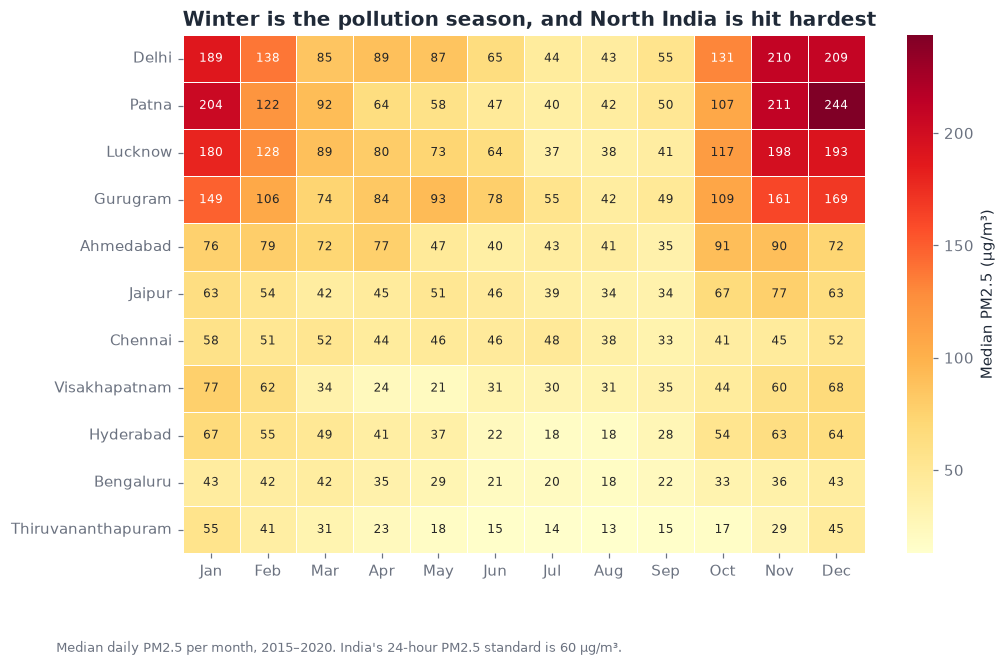

In [2]:
profile = events.monthly_profile(df, "PM2.5")
profile.to_csv(TABLES / "monthly_pm25.csv")
plots.monthly_heatmap(profile, FIG / "08_monthly_pm25.png");

In [3]:
swing = events.seasonal_swing(profile).sort_values(ascending=False)
pd.DataFrame({"worst month": profile.idxmax(axis=1), "best month": profile.idxmin(axis=1),
              "worst / best": swing}).loc[swing.index]

,worst month,best month,worst / best
City,,,
Patna,12,7,6.13
Lucknow,11,7,5.42
Delhi,11,8,4.88
Thiruvananthapuram,1,8,4.30
Gurugram,12,8,4.03
Hyderabad,1,8,3.81
Visakhapatnam,1,5,3.66
Ahmedabad,10,9,2.61
Bengaluru,1,8,2.33


- **Winter is the pollution season almost everywhere**: every city's worst month falls between October and January. The **monsoon months (July-September) are the cleanest**, as rain washes particles out of the air.
- **The Indo-Gangetic plain (Delhi, Patna, Lucknow, Gurugram) is in a different league.** Their worst-month medians are about 170-245 µg/m³, three to four times India's 24-hour standard of 60 µg/m³, and four to six times their own best month.
- Southern cities such as Bengaluru, Chennai and Thiruvananthapuram have monthly medians below the 60 µg/m³ standard all year round.

## 2. Diwali: raw numbers in Delhi

Daily PM2.5 in Delhi, by day relative to Diwali (day 0):

In [4]:
delhi = events.event_window(df[df["City"] == "Delhi"], "PM2.5")
delhi.pivot_table(index="event_year", columns="day", values="value").round(0)

day,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7
event_year,,,,,,,,,,,,,,,
2015,293.0,162.0,153.0,354.0,218.0,201.0,250.0,220.0,258.0,292.0,222.0,214.0,184.0,136.0,188.0
2016,182.0,165.0,116.0,209.0,296.0,319.0,350.0,356.0,435.0,395.0,538.0,482.0,342.0,588.0,685.0
2017,107.0,137.0,147.0,148.0,153.0,122.0,152.0,176.0,NaN,213.0,146.0,163.0,188.0,203.0,179.0
2018,225.0,237.0,205.0,160.0,97.0,362.0,178.0,175.0,420.0,301.0,289.0,257.0,272.0,265.0,136.0
2019,98.0,115.0,94.0,122.0,174.0,130.0,149.0,199.0,301.0,288.0,279.0,314.0,388.0,320.0,582.0


Two things stand out:

- **The festival peak usually comes the day *after* Diwali**: in 2017, 2018 and 2019, day +1 is the highest of the days −3…+3. Each value is a 24-hour average and the fireworks are in the evening, so most of the smoke lands in the following day's reading.
- **Pollution keeps rising for weeks regardless.** In 2016 and 2019, days +5 to +7 are worse than Diwali itself. That is stubble-burning season (the November 2016 Delhi smog is visible here). Comparing Diwali with "two weeks earlier" would wrongly credit that seasonal rise to the festival.

## 3. Separating the festival from the season

Each Diwali is compared with a **local baseline**: the average of days −7…−3 and +4…+7. Because the baseline straddles the festival, a steady seasonal rise cancels out. (A test in `tests/test_events.py` checks that a pure upward trend produces no false spike.)

In [5]:
spike = events.diwali_spike(df)
spike.to_csv(TABLES / "diwali_spike.csv")
spike

,Region,years,peak_day,peak_ratio,day_before,diwali_day,day_after
City,,,,,,,
Visakhapatnam,South,3,0,2.38,0.75,2.38,1.29
Ahmedabad,West,3,1,2.01,1.15,1.59,2.01
Bengaluru,South,5,1,1.92,0.96,1.45,1.92
Chennai,South,5,-1,1.86,1.86,1.30,1.08
Jaipur,North,3,2,1.67,1.01,1.15,1.64
Lucknow,North,5,1,1.63,1.12,1.22,1.63
Patna,East,5,1,1.54,0.93,1.10,1.54
Hyderabad,South,5,1,1.45,1.11,1.39,1.45
Delhi,North,5,2,1.35,0.96,1.04,1.25


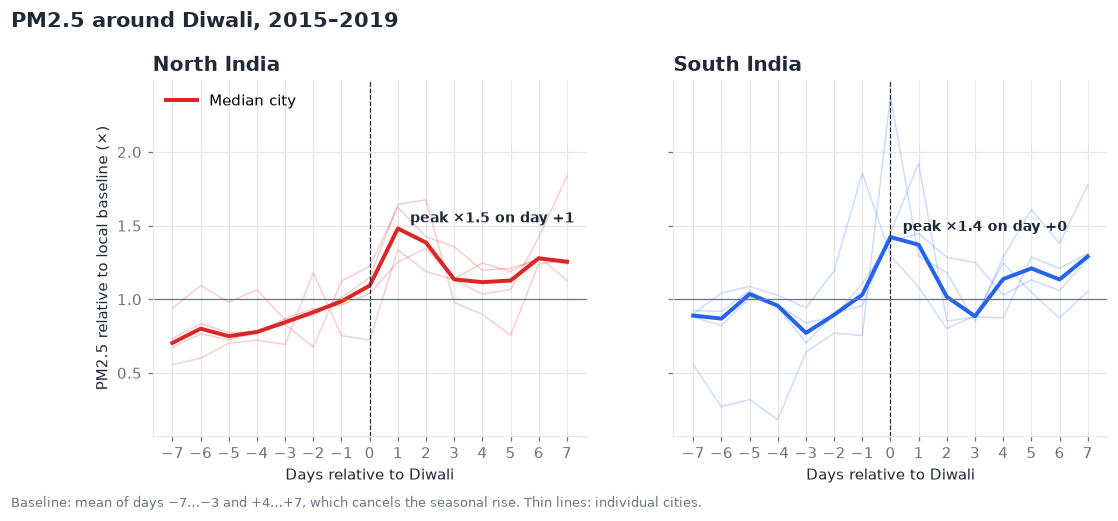

In [6]:
north = spike.index[spike["Region"] == "North"].tolist()
south = spike.index[spike["Region"] == "South"].tolist()
plots.diwali_profiles({"North India": events.event_profile(df, north),
                       "South India": events.event_profile(df, south)},
                      FIG / "07_diwali_profiles.png");

**Findings**

- **Diwali adds a short, sharp spike** of roughly **1.3-2.4x** the surrounding level in the ten cities with enough data, most often on the day after Diwali.
- **Chennai peaks the day *before* Diwali.** That is consistent with Tamil Nadu celebrating Deepavali on Naraka Chaturdashi, one day before the North Indian date used here, a nice check that the method picks up real behaviour.
- **In Delhi the festival is a small part of the problem.** Delhi's typical spike (about 1.3x its local baseline) is smaller than in several southern cities, not because Delhi celebrates less but because its baseline is already so high. The weeks around Diwali are dominated by the seasonal smog.

## 4. Limitations

- **The baseline is conservative.** Days +4…+7 may still contain festival smoke, which raises the baseline and makes spikes look smaller. These estimates are lower bounds.
- Only **five Diwalis** (2015-2019), and fewer for most cities because of missing data.
- **No weather adjustment**: a windy or rainy Diwali reduces the spike in a given year. Taking the median across years limits, but does not remove, this effect.